### 1. Instalasi dan persiapan library

In [32]:

!pip install textsearch
!pip install contractions
!pip install textsearch

import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

- pip install textsearch dan pip install contractions: memasang library yang dibutuhkan untuk pemrosesan teks.
- import nltk: memanggil library NLTK untuk membantu mengolah teks.
- nltk.download('punkt'): mengunduh data untuk memisahkan teks menjadi kata-kata.
- nltk.download('punkt_tab'): mengunduh data pendukung tokenisasi.
- nltk.download('stopwords'): mengunduh daftar kata umum bahasa Inggris yang nantinya bisa diabaikan, seperti the, is, dan and.

### 2. Load and View Dataset

In [33]:

import pandas as pd

df = pd.read_csv('tmdb_5000_movies.csv.gz', compression='gzip')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   str    
 2   homepage              1712 non-null   str    
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   str    
 5   original_language     4803 non-null   str    
 6   original_title        4803 non-null   str    
 7   overview              4800 non-null   str    
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   str    
 10  production_countries  4803 non-null   str    
 11  release_date          4802 non-null   str    
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   str    
 15  status                4803 non-n

- import pandas as pd: memanggil library Pandas untuk membaca dan mengolah data berbentuk tabel.
- pd.read_csv(...): membaca dataset film TMDB dari file tmdb_5000_movies.csv.gz.
- compression='gzip': memberi tahu Pandas bahwa file tersebut menggunakan kompresi gzip.
- df.info(): menampilkan informasi dataset, seperti jumlah baris, kolom, nilai yang tidak kosong, dan tipe data.

### 3. Memuat dataset

In [34]:

df.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


Hasil yang diharapkan adalah 4.803 baris dan 20 kolom sebelum seleksi kolom.

### 4. Memilih kolom dan membuat deskripsi film

In [38]:

df = pd.read_csv('tmdb_5000_movies.csv.gz', compression='gzip')

df = df[['title', 'tagline', 'overview', 'popularity']]

df['tagline'] = df['tagline'].fillna('')

df['description'] = df['tagline'].map(str) + ' ' + df['overview']

df.dropna(inplace=True)

df.info()


<class 'pandas.DataFrame'>
Index: 4800 entries, 0 to 4802
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        4800 non-null   str    
 1   tagline      4800 non-null   str    
 2   overview     4800 non-null   str    
 3   popularity   4800 non-null   float64
 4   description  4800 non-null   str    
dtypes: float64(1), str(4)
memory usage: 225.0 KB


Hasil yang diharapkan: 4.800 baris dan 5 kolom, yaitu title, tagline, overview, popularity, dan description.

In [39]:
df.head()

,title,tagline,overview,popularity,description
0,Avatar,Enter the World of Pandora.,"In the 22nd century, a paraplegic Marine is di...",150.437577,Enter the World of Pandora. In the 22nd centur...
1,Pirates of the Caribbean: At World's End,"At the end of the world, the adventure begins.","Captain Barbossa, long believed to be dead, ha...",139.082615,"At the end of the world, the adventure begins...."
2,Spectre,A Plan No One Escapes,A cryptic message from Bond’s past sends him o...,107.376788,A Plan No One Escapes A cryptic message from B...
3,The Dark Knight Rises,The Legend Ends,Following the death of District Attorney Harve...,112.312950,The Legend Ends Following the death of Distric...
4,John Carter,"Lost in our world, found in another.","John Carter is a war-weary, former military ca...",43.926995,"Lost in our world, found in another. John Cart..."


df.head() digunakan untuk melihat 5 baris pertama dari dataset. Kita memeriksa contoh data film dan memastikan kolom seperti title, overview, tagline, dan popularity tersedia sebelum mengolah teksnya.

### 5. Import library dan membuat fungsi normalisasi teks

In [41]:

import nltk
import re
import numpy as np
import contractions

stop_words = nltk.corpus.stopwords.words('english')

def normalize_document(doc):
    doc = re.sub(r'[^a-zA-Z0-9\s]', '', doc, re.I | re.A)
    doc = doc.lower()
    doc = doc.strip()
    doc = contractions.fix(doc)
    tokens = nltk.word_tokenize(doc)
    filtered_tokens = [token for token in tokens if token not in stop_words]
    doc = ' '.join(filtered_tokens)
    return doc

normalize_corpus = np.vectorize(normalize_document)

norm_corpus = normalize_corpus(list(df['description']))
len(norm_corpus)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13780\4066156443.py:9: DeprecationWarning: 'count' is passed as positional argument
  doc = re.sub(r'[^a-zA-Z0-9\s]', '', doc, re.I | re.A)


4800

Fungsi normalize_document() digunakan untuk membersihkan teks deskripsi film melalui beberapa proses:
1. Menghapus tanda baca yang tidak diperlukan.
2. Mengubah teks menjadi huruf kecil, supaya Movie dan movie dianggap sama.
3. Menghapus spasi berlebih di awal dan akhir teks.
4. Memperbaiki singkatan bahasa Inggris, misalnya don't menjadi do not.
5. Memisahkan kalimat menjadi kata-kata menggunakan tokenisasi.
6. Menghapus stopwords, yaitu kata umum bahasa Inggris yang tidak terlalu membantu membedakan deskripsi film.
7. Menggabungkan kembali kata-kata yang tersisa menjadi teks.
Sementara itu, np.vectorize(normalize_document) menyiapkan fungsi agar dapat diterapkan ke banyak deskripsi film.

### 6. Mengubah teks menjadi angka dengan CountVectorizer

In [42]:

from sklearn.feature_extraction.text import CountVectorizer

stop_words = stop_words + ['one', 'two', 'three', 'four', 'five', 'get']

cv = CountVectorizer(
    ngram_range=(1, 2),
    min_df=0.001,
    max_df=0.99,
    stop_words=stop_words
)

cv_matrix = cv.fit_transform(norm_corpus)

cv_matrix.shape

(4800, 6100)

1. CountVectorizer: mengubah kata-kata menjadi angka berdasarkan frekuensi kemunculannya.
2. ngram_range=(1, 2): memperhitungkan kata tunggal dan pasangan kata, misalnya movie dan science fiction.
3. min_df=0.001: mengabaikan kata yang muncul pada kurang dari 0,1% dokumen.
4. max_df=0.99: mengabaikan kata yang muncul pada lebih dari 99% dokumen.
5. stop_words=stop_words: mengabaikan kata-kata umum yang sudah ditentukan.
6. cv.fit_transform(norm_corpus): mempelajari kosakata dan mengubah 4.800 deskripsi menjadi matriks angka.
7. cv_matrix.shape: menampilkan ukuran matriks tersebut.

### 7. Melakukan clustering dengan K-Means

In [44]:

from sklearn.cluster import KMeans

NUM_CLUSTERS = 6

km = KMeans(
    n_clusters=NUM_CLUSTERS,
    max_iter=10000,
    n_init=100,
    random_state=42
).fit(cv_matrix)
km

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",6
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",100
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",10000
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](6, 6100)",

1. KMeans: algoritma untuk mengelompokkan data berdasarkan kemiripan.
2. n_clusters=6: membagi film menjadi 6 kelompok.
3. max_iter=10000: batas maksimum iterasi untuk mencari pengelompokan yang sesuai.
4. n_init=100: mencoba 100 inisialisasi berbeda untuk mencari hasil clustering yang lebih baik.
5. random_state=42: menetapkan nilai awal agar hasil lebih konsisten jika lingkungan dan datanya sama.
6. km.fit(cv_matrix): menjalankan proses clustering terhadap matriks teks.
7. Counter(km.labels_): menghitung jumlah film di setiap kelompok.

### 8. Menghitung jumlah film di setiap cluster

In [45]:

from collections import Counter

Counter(km.labels_)

Counter({np.int32(0): 2677,
         np.int32(3): 656,
         np.int32(4): 525,
         np.int32(5): 473,
         np.int32(1): 468,
         np.int32(2): 1})

- Counter menghitung jumlah kemunculan setiap label.
- km.labels_ berisi nomor kelompok untuk setiap film.
- Output-nya menunjukkan berapa banyak film masuk ke cluster 0, 1, 2, 3, 4, dan 5.

### 9. Menambahkan label cluster ke dataset

In [52]:

df['kmeans_cluster'] = km.labels_


kode ini menambahkan kolom cluster ke dataset. Setiap film akan memiliki nomor kelompok dari 0 sampai 5, sehingga kita dapat melihat film mana yang masuk ke kelompok tertentu.

### 10. Mengurutkan film berdasarkan cluster dan popularitas

In [54]:

movie_clusters = (df[['title', 'kmeans_cluster', 'popularity']]
                  .sort_values(by=['kmeans_cluster', 'popularity'],
                               ascending=False)
                  .groupby('kmeans_cluster').head(20))

movie_clusters = movie_clusters.copy(deep=True)


- Memilih kolom judul, nomor cluster, dan popularitas.
- Mengurutkan data berdasarkan cluster dan popularitas dari terbesar ke terkecil.
- Mengambil maksimal 20 film dari setiap cluster.
- copy(deep=True) membuat salinan data untuk diproses selanjutnya.

### 11. Menampilkan kata kunci dan film populer setiap cluster

In [55]:

feature_names = cv.get_feature_names_out()
topn_features = 30
ordered_centroids = km.cluster_centers_.argsort()[:, ::-1]

# get key features for each cluster
# get movies belonging to each cluster
for cluster_num in range(NUM_CLUSTERS):
    key_features = [feature_names[index]
                    for index in ordered_centroids[cluster_num, :topn_features]]

    movies = movie_clusters[
        movie_clusters['kmeans_cluster'] == cluster_num
    ]['title'].values.tolist()

    print('CLUSTER #' + str(cluster_num + 1))
    print('Key Features:', key_features)
    print('Popular Movies:', movies)
    print('-' * 80)

CLUSTER #1
Key Features: ['young', 'story', 'love', 'family', 'find', 'must', 'time', 'back', 'friends', 'years', 'way', 'film', 'home', 'help', 'lives', 'town', 'father', 'take', 'finds', 'hes', 'school', 'first', 'woman', 'never', 'group', 'together', 'team', 'go', 'make', 'takes']
Popular Movies: ['Interstellar', 'Guardians of the Galaxy', 'Pirates of the Caribbean: The Curse of the Black Pearl', 'Dawn of the Planet of the Apes', 'The Hunger Games: Mockingjay - Part 1', 'Big Hero 6', 'Whiplash', 'The Dark Knight', 'The Martian', "Pirates of the Caribbean: Dead Man's Chest", 'X-Men: Apocalypse', 'Rise of the Planet of the Apes', 'The Lord of the Rings: The Fellowship of the Ring', 'Pirates of the Caribbean: On Stranger Tides', "One Flew Over the Cuckoo's Nest", 'The Hunger Games: Mockingjay - Part 2', 'Star Wars', 'Brave', 'The Lord of the Rings: The Return of the King', 'The Hobbit: The Battle of the Five Armies']
---------------------------------------------------------------------

- feature_names mengambil daftar kata dan pasangan kata dari CountVectorizer.
- topn_features = 30 menentukan jumlah 30 kata atau fitur teratas per cluster.
- ordered_centroids mengurutkan fitur berdasarkan nilai pusat cluster K-Means.
- Perulangan for menampilkan kata kunci dan judul film populer untuk keenam cluster.

# Clustering with Embeddings

### 1. Instal gensim

In [56]:
!pip install gensim

   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   - -------------------------------------- 0.8/24.4 MB 6.3 MB/s eta 0:00:04
   --- ------------------------------------ 2.1/24.4 MB 7.6 MB/s eta 0:00:03
   ------ --------------------------------- 3.7/24.4 MB 7.6 MB/s eta 0:00:03
   ---------- ----------------------------- 6.3/24.4 MB 8.6 MB/s eta 0:00:03
   ----------- ---------------------------- 7.1/24.4 MB 7.6 MB/s eta 0:00:03
   ------------ --------------------------- 7.3/24.4 MB 6.6 MB/s eta 0:00:03
   ------------ --------------------------- 7.6/24.4 MB 6.2 MB/s eta 0:00:03
   -------------- ------------------------- 8.7/24.4 MB 5.6 MB/s eta 0:00:03
   ---------------- ----------------------- 10.2/24.4 MB 5.7 MB/s eta 0:00:03
   -------------------- ------------------- 12.3/24.4 MB 6.2 MB/s eta 0:00:02
   ---------------------- ----------------- 13.6/24.4 MB 6.1 MB/s eta 0:00:02
   -------------------------- ------------- 16.0/24.4 MB 6.6 MB/s eta 0:00:02
  


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 2. Membangun Model FastText untuk Representasi Vektor Teks Film

In [57]:
from gensim.models import FastText

tokenized_docs = [normalize_document(doc).split() for doc in df['description']]
ft_model = FastText(tokenized_docs, vector_size=300, window=40, min_count=3, workers=4, sg=1, epochs=100)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13780\4066156443.py:9: DeprecationWarning: 'count' is passed as positional argument
  doc = re.sub(r'[^a-zA-Z0-9\s]', '', doc, re.I | re.A)


- vector_size=300: setiap kata direpresentasikan dengan 300 angka.
- window=40: model mempertimbangkan konteks kata di sekitarnya dengan ukuran jendela 40.
- min_count=3: kata harus muncul minimal 3 kali agar dipelajari.
- workers=4: menggunakan 4 pekerja untuk proses pelatihan.
- sg=1: menggunakan metode Skip-gram.
- epochs=100: model dilatih sebanyak 100 putaran.

### 3. Mengubah Kata Menjadi Vektor Rata-Rata FastText

In [61]:

def averaged_word2vec_vectorizer(corpus, model, num_features):
    vocabulary = set(model.wv.index_to_key)

    def average_word_vectors(words, model, vocabulary, num_features):
        feature_vector = np.zeros((num_features,), dtype="float64")
        nwords = 0.

        for word in words:
            if word in vocabulary:
                nwords += 1.
                feature_vector = np.add(feature_vector, model.wv[word])

        if nwords:
            feature_vector = np.divide(feature_vector, nwords)

        return feature_vector

    features = [
        average_word_vectors(tokenized_sentence, model, vocabulary, num_features)
        for tokenized_sentence in corpus
    ]

    return np.array(features)


Kode ini membuat fungsi untuk mengubah kumpulan kata dalam setiap deskripsi film menjadi satu vektor numerik. Caranya dengan mengambil vektor setiap kata yang dikenal oleh model FastText, kemudian menghitung rata-ratanya.
- vocabulary: mengambil daftar kata yang dikenal oleh model FastText.
- average_word_vectors(): menghitung rata-rata vektor dari kata-kata dalam satu deskripsi.
- nwords: menghitung jumlah kata yang berhasil ditemukan dalam kosakata model.
- np.array(features): menggabungkan hasil vektor dari seluruh deskripsi film menjadi sebuah array numerik.

### 4. Mengubah Deskripsi Film Menjadi Vektor FastText

In [62]:
doc_vecs_ft = averaged_word2vec_vectorizer(tokenized_docs, ft_model, 300)
doc_vecs_ft.shape

(4800, 300)

kode ini mengubah 4.800 deskripsi film menjadi vektor numerik dengan 300 dimensi per film.
Jika output-nya (4800, 300), artinya terdapat 4.800 film, dan setiap film direpresentasikan oleh 300 nilai numerik. Hasil ini kemudian digunakan untuk proses clustering.

### 5. Melakukan Clustering Film Menggunakan FastText dan K-Means

In [63]:

NUM_CLUSTERS = 6
km = KMeans(n_clusters=NUM_CLUSTERS, max_iter=10000, n_init=100, random_state=42).fit(doc_vecs_ft)

kode ini mengelompokkan 4.800 film ke dalam 6 cluster berdasarkan kemiripan representasi numeriknya. Film dalam cluster yang sama diharapkan memiliki deskripsi yang relatif mirip.

### 6. Menghitung Jumlah Film pada Setiap Cluster

In [64]:
Counter(km.labels_)

Counter({np.int32(3): 1270,
         np.int32(0): 1003,
         np.int32(1): 877,
         np.int32(2): 586,
         np.int32(5): 550,
         np.int32(4): 514})

kode ini menampilkan distribusi jumlah film dalam 6 cluster, sehingga kita dapat mengetahui berapa banyak film yang dikelompokkan ke cluster 0, 1, 2, 3, 4, dan 5.

### 7. Menampilkan 30 Film Teratas pada Setiap Cluster

In [65]:
df['kmeans_cluster'] = km.labels_
movie_clusters = (df[['title', 'kmeans_cluster', 'popularity']]
 .sort_values(by=['kmeans_cluster', 'popularity'],
 ascending=False)
 .groupby('kmeans_cluster').head(30))
movie_clusters = movie_clusters.copy(deep=True)

kode ini menampilkan maksimal 30 film terpopuler dari masing-masing cluster untuk membantu melihat dan memahami hasil pengelompokan film.

### 8. Menampilkan Daftar Film Populer pada Setiap Cluster

In [66]:
for cluster_num in range(NUM_CLUSTERS):
 movies = movie_clusters[movie_clusters['kmeans_cluster'] == cluster_num]['title'].values.tolist()
 print('CLUSTER #'+str(cluster_num+1))
 print('Popular Movies:', movies)
 print('-'*80)

CLUSTER #1
Popular Movies: ['Minions', 'Whiplash', 'Fight Club', 'Gone Girl', "Harry Potter and the Philosopher's Stone", 'Bruce Almighty', 'Fifty Shades of Grey', 'Psycho', 'Birdman', 'Monsters University', 'Nightcrawler', 'Finding Nemo', 'The Devil Wears Prada', 'Cars', 'Spider-Man', 'The Hangover', 'Horrible Bosses 2', 'Home Alone 2: Lost in New York', 'Back to the Future', 'Toy Story', 'Toy Story 2', 'Rocky', 'Pitch Perfect 2', 'Ted 2', 'Grease', 'Ratatouille', 'Southpaw', 'Paper Towns', 'Silver Linings Playbook', 'Nerve']
--------------------------------------------------------------------------------
CLUSTER #2
Popular Movies: ['The Dark Knight', 'Inception', 'The Avengers', 'The Godfather', 'Pixels', 'Despicable Me 2', 'The Shawshank Redemption', "One Flew Over the Cuckoo's Nest", 'Mission: Impossible - Rogue Nation', 'Despicable Me', 'The Dark Knight Rises', 'Quantum of Solace', 'Spectre', 'Furious 7', "We're the Millers", 'I, Robot', 'The Wolf of Wall Street', 'Skyfall', 'The 

kode ini menampilkan judul-judul film populer dari masing-masing 6 cluster, sehingga kita bisa melihat film apa saja yang dikelompokkan bersama berdasarkan kemiripan deskripsinya.

# Hierarchical Clustering

### 1. Mengimpor Library untuk Hierarchical Clustering

In [67]:

from scipy.cluster.hierarchy import ward, dendrogram
from sklearn.metrics.pairwise import cosine_similarity

Kode ini mengimpor fungsi dan metode yang diperlukan untuk melakukan pengelompokan film menggunakan Hierarchical Clustering serta menghitung kemiripan antarvektor deskripsi film.
- ward: digunakan untuk menggabungkan kelompok data secara bertahap berdasarkan metode Ward.
- dendrogram: digunakan untuk menampilkan diagram pohon yang menggambarkan proses pengelompokan data.
- cosine_similarity: digunakan untuk menghitung tingkat kemiripan antara vektor deskripsi film.

### 2. Membuat Fungsi Hierarchical Clustering Menggunakan Metode Ward

In [68]:
def ward_hierarchical_clustering(feature_matrix):
 cosine_distance = 1 - cosine_similarity(feature_matrix)
 linkage_matrix = ward(cosine_distance)
 return linkage_matrix

Kode ini membuat fungsi untuk mengelompokkan data film secara bertahap menggunakan metode Hierarchical Clustering. Fungsi ini menghitung jarak berdasarkan kemiripan vektor deskripsi film, kemudian menghasilkan matriks yang menyimpan informasi proses pengelompokan.

### 3. Membuat Visualisasi Dendrogram untuk Hierarchical Clustering

In [70]:

import matplotlib.pyplot as plt
%matplotlib inline

def plot_hierarchical_clusters(linkage_matrix, movie_data, p=100, figure_size=(8,12)):
    # set size
    fig, ax = plt.subplots(figsize=figure_size)
    movie_titles = movie_data['title'].values.tolist()

    # plot dendrogram
    R = dendrogram(
        linkage_matrix,
        orientation="left",
        labels=movie_titles,
        truncate_mode='lastp',
        p=p,
        no_plot=True
    )

    temp = {
        R["leaves"][ii]: movie_titles[ii]
        for ii in range(len(R["leaves"]))
    }

    def llf(xx):
        return "{}".format(temp[xx])

    ax = dendrogram(
        linkage_matrix,
        truncate_mode='lastp',
        orientation="left",
        p=p,
        leaf_label_func=llf,
        leaf_font_size=10.,
    )

    plt.tick_params(
        axis='x',
        which='both',
        bottom='off',
        top='off',
        labelbottom='off'
    )

    plt.tight_layout()
    plt.savefig('movie_hierachical_clusters.png', dpi=200)


Kode ini membuat fungsi untuk menampilkan hasil Hierarchical Clustering film dalam bentuk dendrogram, yaitu diagram pohon yang menunjukkan proses pengelompokan film.

### 4. Menghitung Hierarchical Clustering pada Vektor FastText

In [71]:
linkage_matrix = ward_hierarchical_clustering(doc_vecs_ft)

Kode ini menjalankan fungsi ward_hierarchical_clustering() untuk melakukan proses Hierarchical Clustering berdasarkan vektor numerik dari deskripsi film yang telah dihasilkan oleh FastText.
- doc_vecs_ft: berisi representasi numerik dari 4.800 deskripsi film dengan 300 dimensi.
- ward_hierarchical_clustering(...): menghitung jarak antarvektor dan menjalankan proses pengelompokan menggunakan metode Ward.
- linkage_matrix: menyimpan informasi hasil penggabungan kelompok yang nantinya digunakan untuk membuat dendrogram.

### 5. Menampilkan Matriks Hasil Hierarchical Clustering

In [72]:
np.set_printoptions(suppress=True)
print(linkage_matrix)

[[ 667.         2991.            1.37079784    2.        ]
 [1620.         2119.            1.55699641    2.        ]
 [1452.         4165.            1.64065975    2.        ]
 ...
 [4399.         9594.           42.70808593 1699.        ]
 [9592.         9595.           46.25161052 3101.        ]
 [9596.         9597.           94.54780377 4800.        ]]


Kode ini digunakan untuk menampilkan isi linkage_matrix, yaitu matriks yang menyimpan informasi proses penggabungan kelompok film dalam Hierarchical Clustering.

### 6. Memvisualisasikan Hasil Hierarchical Clustering dengan Dendrogram

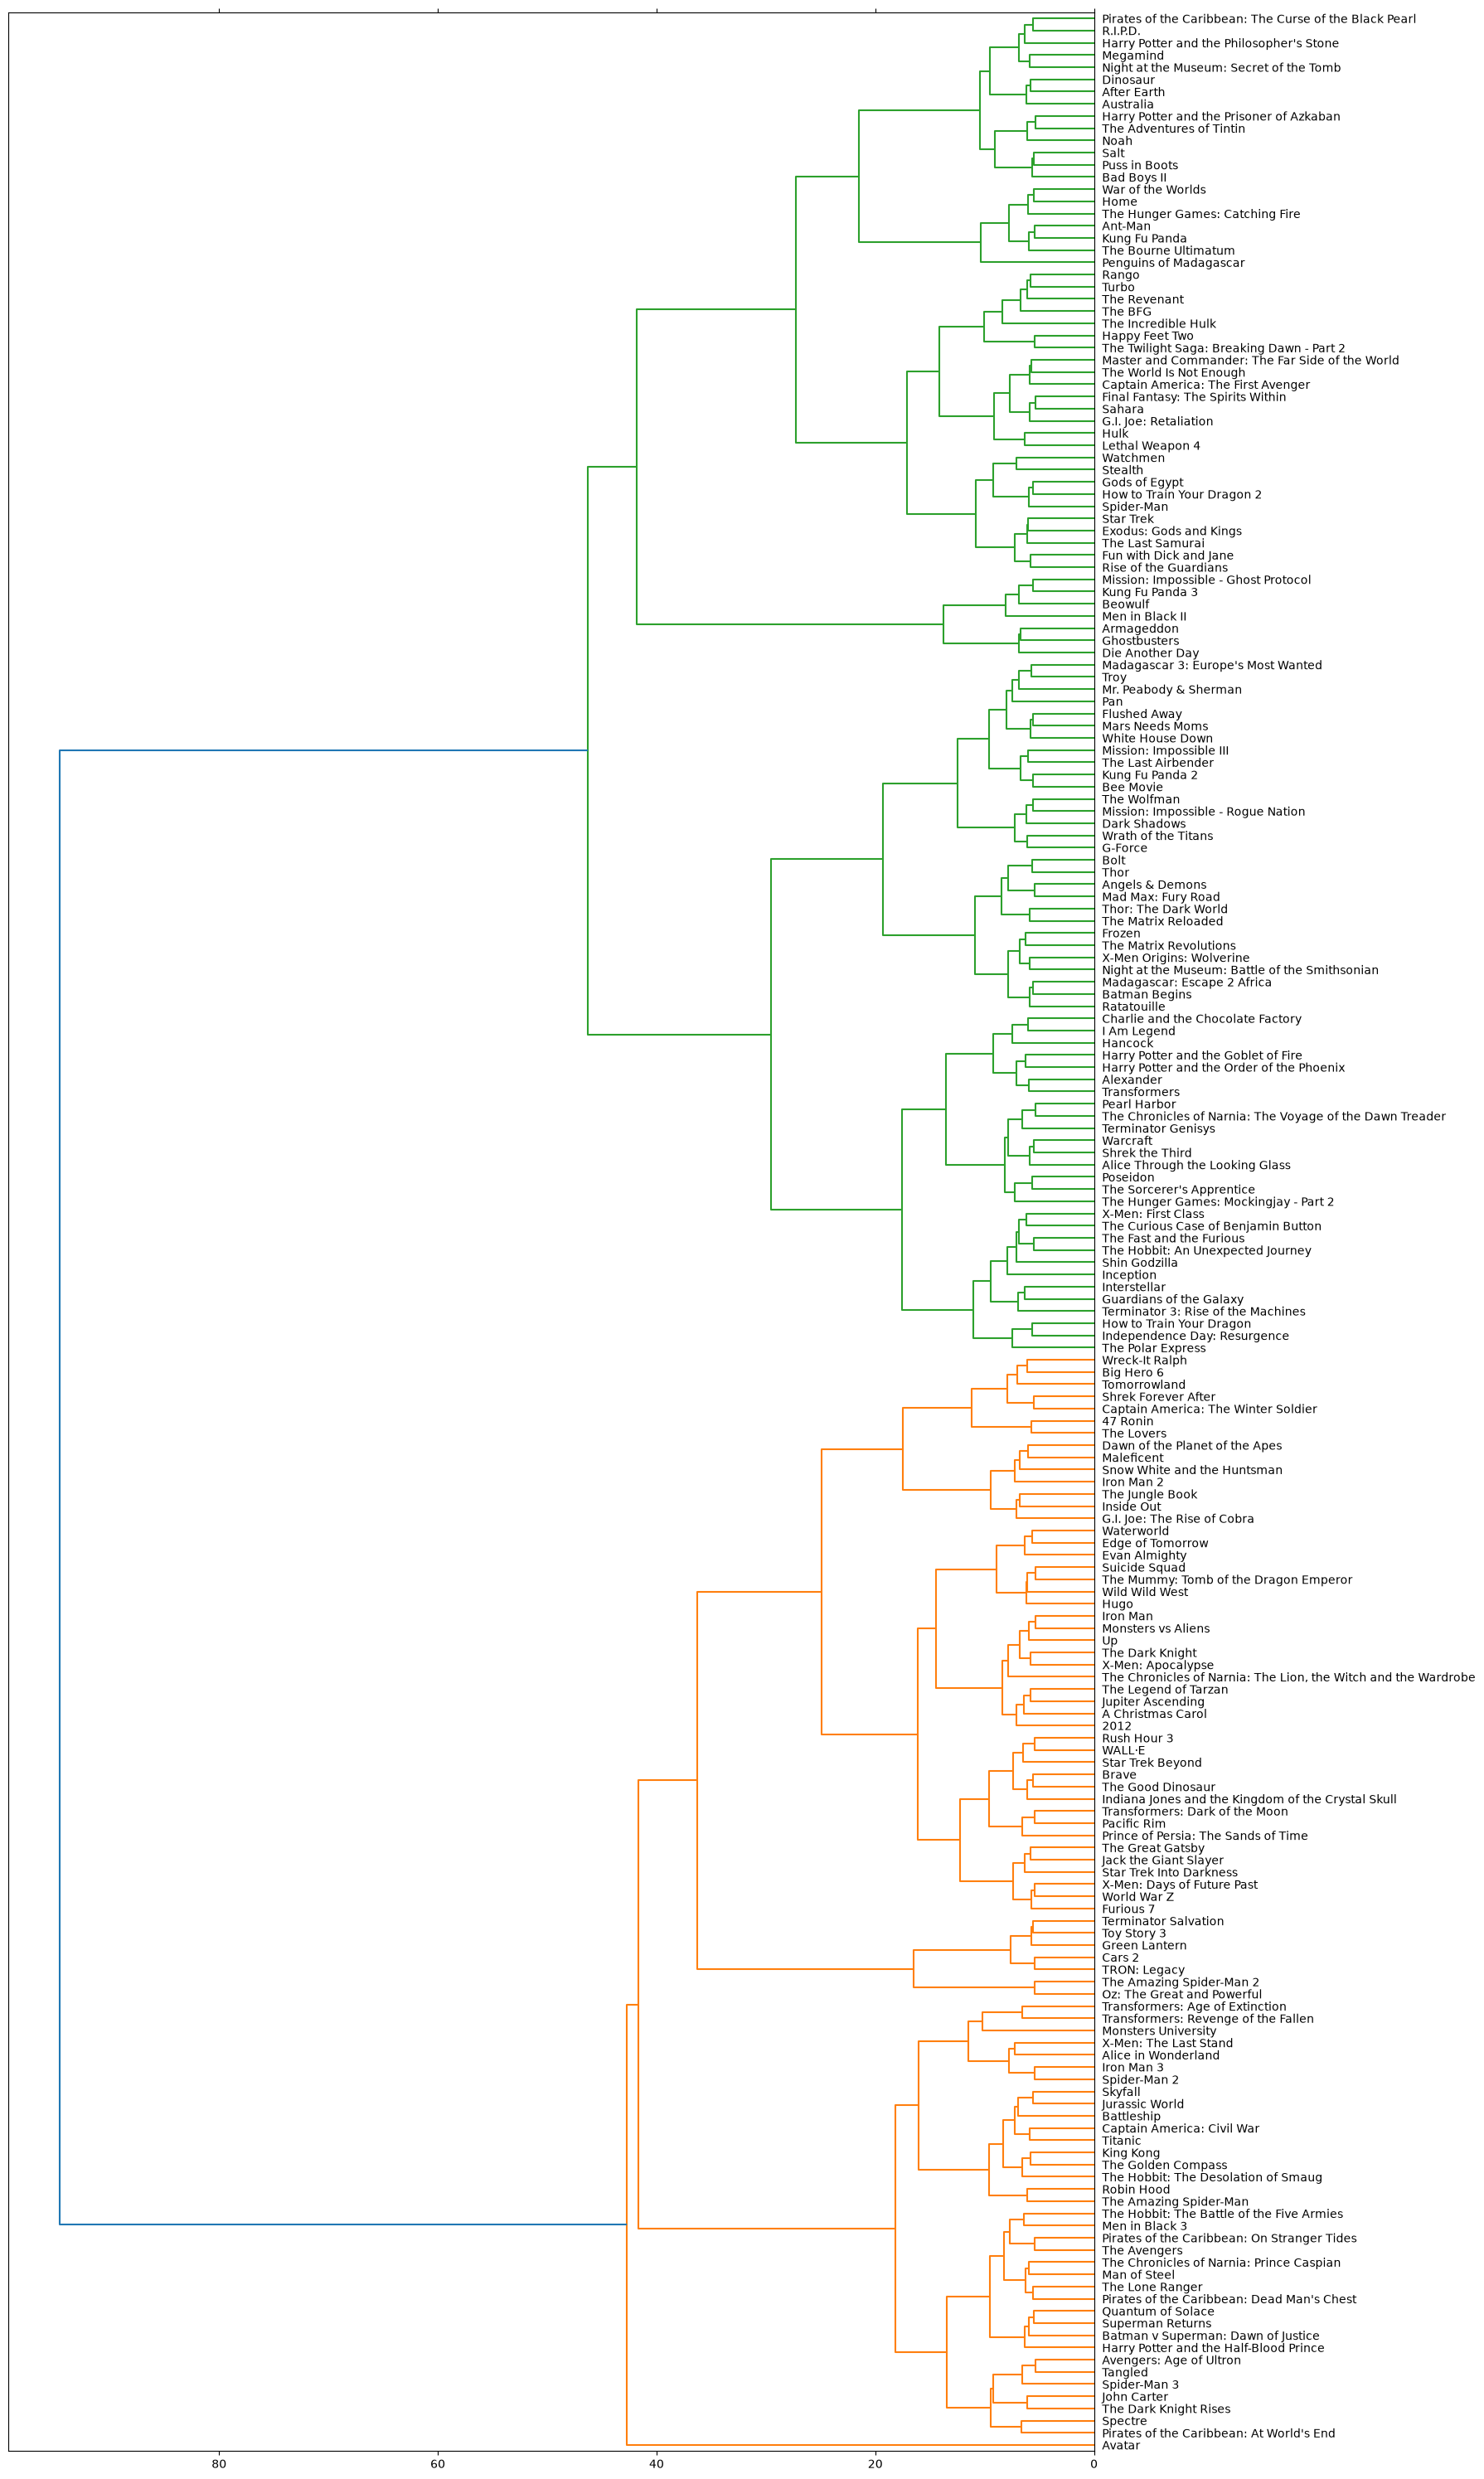

In [74]:
plot_hierarchical_clusters(
    linkage_matrix,
    p=200,
    movie_data=df,
    figure_size=(18, 30)
)

Kode ini menjalankan fungsi plot_hierarchical_clusters() untuk menampilkan hasil pengelompokan film dalam bentuk dendrogram. Grafik ini membantu melihat bagaimana kelompok film terbentuk berdasarkan kemiripan vektor deskripsinya.
- linkage_matrix: berisi informasi hasil proses Hierarchical Clustering.
- p=200: membatasi tampilan dendrogram menjadi maksimal 200 cabang atau kelompok terakhir.
- movie_data=df: menggunakan dataset film sebagai sumber judul film.
- figure_size=(18, 30): mengatur ukuran grafik dengan lebar 18 inci dan tinggi 30 inci.